In [1]:
# !pip3 install seaborn
# !pip3 install matplotlib
!pip3 install openpyxl


[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

In [4]:
df_2024 = pd.read_excel("ttc-subway-delay-data-2024.xlsx", sheet_name="Subway")
df_2025 = pd.read_csv("ttc-subway-delay-data-since-2025.csv")

In [5]:
df = pd.concat([df_2024, df_2025], ignore_index=True)
print(f"Combined dataset: {df.shape[0]} records, {df.shape[1]} columns")

Combined dataset: 71942 records, 11 columns


In [6]:
df.head()

,Date,Time,Day,Station,Code,Min Delay,Min Gap,Bound,Line,Vehicle,_id
0,2024-01-01 00:00:00,02:00,Monday,SHEPPARD STATION,MUI,0,0,N,YU,5491,NaN
1,2024-01-01 00:00:00,02:00,Monday,DUNDAS STATION,MUIS,0,0,N,YU,0,NaN
2,2024-01-01 00:00:00,02:08,Monday,DUNDAS STATION,MUPAA,4,10,N,YU,6051,NaN
3,2024-01-01 00:00:00,02:13,Monday,KENNEDY BD STATION,PUTDN,10,16,E,BD,5284,NaN
4,2024-01-01 00:00:00,02:22,Monday,BLOOR STATION,MUPAA,4,10,N,YU,5986,NaN


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71942 entries, 0 to 71941
Data columns (total 11 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       71942 non-null  object 
 1   Time       71942 non-null  object 
 2   Day        71942 non-null  object 
 3   Station    71942 non-null  object 
 4   Code       71942 non-null  object 
 5   Min Delay  71942 non-null  int64  
 6   Min Gap    71942 non-null  int64  
 7   Bound      46562 non-null  object 
 8   Line       71721 non-null  object 
 9   Vehicle    71942 non-null  int64  
 10  _id        45475 non-null  float64
dtypes: float64(1), int64(3), object(7)
memory usage: 6.0+ MB


In [8]:
line_mapping = {
    # Line 1 — Yonge-University
    'YU': 'Line 1', 'YUS': 'Line 1', 'LINE 1': 'Line 1',
    # Line 2 — Bloor-Danforth
    'BD': 'Line 2', 'BLOOR DANFORTH': 'Line 2',
    # Line 4 — Sheppard
    'SHP': 'Line 4', 'SHEP': 'Line 4',
    # Line 3 — Scarborough RT (decommissioned 2023)
    'SRT': 'Line 3',
    # Multi-line: Line 1 / Line 2
    'YU/BD': 'Line 1/2', 'YU/ BD': 'Line 1/2', 'YU / BD': 'Line 1/2',
    'YU & BD': 'Line 1/2', 'YU/BD LINES': 'Line 1/2', 'YU -BD LINES': 'Line 1/2',
    'BD/YU': 'Line 1/2', 'BD/ YU': 'Line 1/2', 'BD / YU': 'Line 1/2',
    'YUS/BD': 'Line 1/2', 'YUS / BD': 'Line 1/2', 'YUS/ BD': 'Line 1/2',
    'BD/YUS': 'Line 1/2', 'BD/ YUS': 'Line 1/2', 'ONGE-UNIVERSITY AND BL': 'Line 1/2',
    # Multi-line: Line 1 / Line 2 / Line 4
    'YU/BD/SHP': 'Line 1/2/4', 'YUS/ BD/ SHP': 'Line 1/2/4',
    # Invalid — bus routes and non-subway entries
    '109 RANEE': None, '20 CLIFFSIDE': None, '29 DUFFERIN': None, 'TRACK LEVEL ACTIVITY': None,
}

In [9]:
df['Line'] = df['Line'].map(line_mapping)
print(f"Unique Line values after maping: {df['Line'].dropna().nunique()}")
df['Line'].value_counts()


Unique Line values after maping: 6


Line
Line 1        37298
Line 2        30749
Line 4         2663
Line 1/2        968
Line 1/2/4       13
Line 3            7
Name: count, dtype: int64

In [10]:
records_before = len(df)
df = df.dropna(subset=['Line'])
print(f"Removed {records_before - len(df)} invalid records {records_before:,} -> {len(df):,}")


Removed 244 invalid records 71,942 -> 71,698


In [11]:
print(df["Min Delay"].describe().round(2))


count    71698.00
mean         2.74
std         11.80
min          0.00
25%          0.00
50%          0.00
75%          4.00
max        900.00
Name: Min Delay, dtype: float64


In [12]:
# 25th and 75th percentiles -- define the middle 50% of the data
Q1 = df['Min Delay'].quantile(0.25)
Q3 = df['Min Delay'].quantile(0.75)

# IQR: spread of the middle 50%
IQR = Q3 - Q1

# Upper fence: standard threshold beyond which a value is an outlier
upper_fence = Q3 + 1.5 * IQR

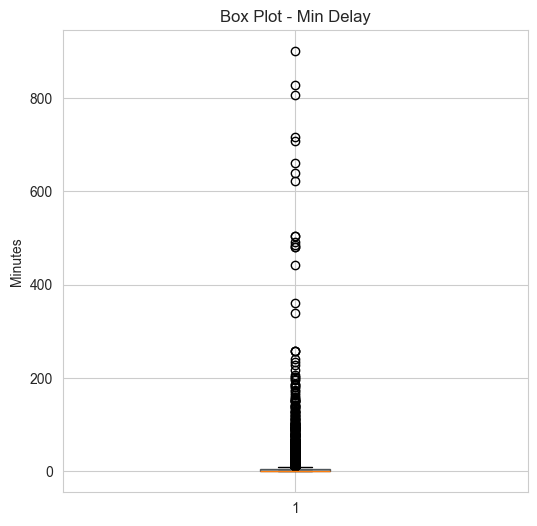

In [13]:
plt.figure(figsize=(6,6))

plt.boxplot(df["Min Delay"],
            vert=True,
            patch_artist=True,
            boxprops=dict(facecolor='steelblue', alpha=0.6))

plt.title("Box Plot - Min Delay")
plt.ylabel("Minutes")
plt.show()

In [14]:
df['min_delay_capped'] = df['Min Delay'].clip(upper=upper_fence)


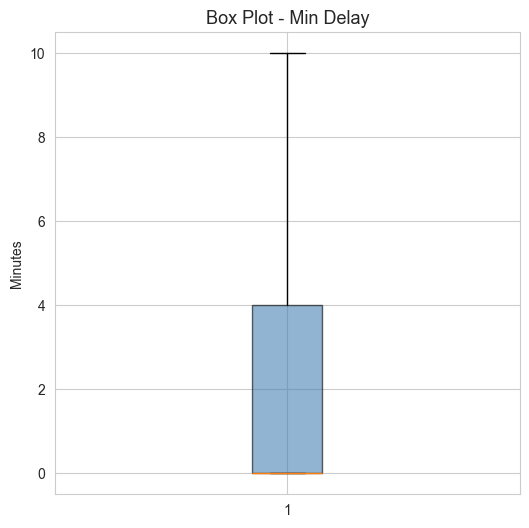

In [15]:
plt.figure(figsize=(6,6))

plt.boxplot(df['min_delay_capped'],
            vert=True, patch_artist=True,
            boxprops=dict(facecolor='steelblue',
            alpha=0.6))

plt.title('Box Plot - Min Delay', fontsize=13)
plt.ylabel('Minutes')
plt.show()


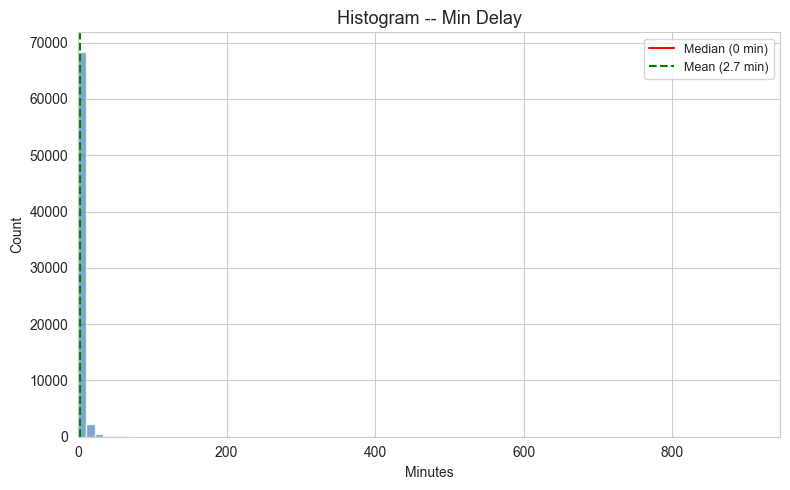

In [16]:
plt.figure(figsize=(8, 5))
plt.hist(df['Min Delay'], bins=80, color='steelblue', alpha=0.7, edgecolor='white')
plt.axvline(df['Min Delay'].median(), color='red', linestyle='-', linewidth=1.5,
            label=f'Median ({df["Min Delay"].median():.0f} min)')
plt.axvline(df['Min Delay'].mean(), color='green', linestyle='--', linewidth=1.5,
            label=f'Mean ({df["Min Delay"].mean():.1f} min)')
plt.title('Histogram -- Min Delay', fontsize=13)
plt.xlabel('Minutes')
plt.ylabel('Count')
plt.legend(fontsize=9)
plt.xlim(left=0)
plt.tight_layout()
plt.show()

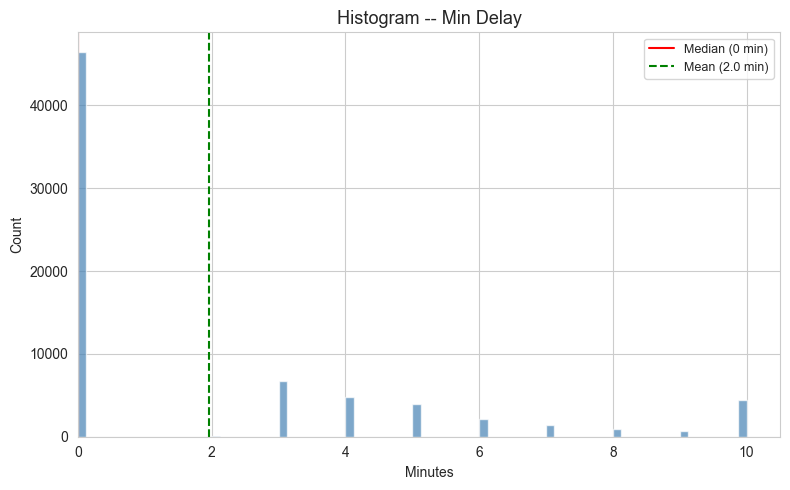

In [17]:
# Histogram -- Min Delay
plt.figure(figsize=(8, 5))
plt.hist(df['min_delay_capped'], bins=80, color='steelblue', alpha=0.7, edgecolor='white')
plt.axvline(df['min_delay_capped'].median(), color='red', linestyle='-', linewidth=1.5,
            label=f'Median ({df["min_delay_capped"].median():.0f} min)')
plt.axvline(df['min_delay_capped'].mean(), color='green', linestyle='--', linewidth=1.5,
            label=f'Mean ({df["min_delay_capped"].mean():.1f} min)')
plt.title('Histogram -- Min Delay', fontsize=13)
plt.xlabel('Minutes')
plt.ylabel('Count')
plt.legend(fontsize=9)
plt.xlim(left=0)
plt.tight_layout()
plt.show()

In [18]:
df = df.drop(columns=['_id', 'Vehicle', 'Bound'])
print(f"Remaining Columns  are: {df.columns.tolist()}")


Remaining Columns  are: ['Date', 'Time', 'Day', 'Station', 'Code', 'Min Delay', 'Min Gap', 'Line', 'min_delay_capped']


In [19]:
df['delay_occured'] = (df['Min Delay'] > 0).astype(int)

In [20]:
print(df['delay_occured'].value_counts())

delay_occured
0    46506
1    25192
Name: count, dtype: int64


In [22]:
print(df['delay_occured'].value_counts(normalize=True).mul(100).round(1).astype(str)+'%')

delay_occured
0    64.9%
1    35.1%
Name: proportion, dtype: object


In [23]:
df.head()

,Date,Time,Day,Station,Code,Min Delay,Min Gap,Line,min_delay_capped,delay_occured
0,2024-01-01 00:00:00,02:00,Monday,SHEPPARD STATION,MUI,0,0,Line 1,0,0
1,2024-01-01 00:00:00,02:00,Monday,DUNDAS STATION,MUIS,0,0,Line 1,0,0
2,2024-01-01 00:00:00,02:08,Monday,DUNDAS STATION,MUPAA,4,10,Line 1,4,1
3,2024-01-01 00:00:00,02:13,Monday,KENNEDY BD STATION,PUTDN,10,16,Line 2,10,1
4,2024-01-01 00:00:00,02:22,Monday,BLOOR STATION,MUPAA,4,10,Line 1,4,1


In [24]:
df['hour'] = df['Time'].apply(lambda t: int(t.split(":")[0]))


In [25]:
day_mapping = {
    'Monday': 0,
    'Tuesday': 1, 
    'Wednesday': 2, 
    'Thursday': 3, 
    'Friday': 4, 
    'Saturday': 5, 
    'Sunday': 6, 
}

df['day_num'] = df['Day'].map(day_mapping)


In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df['station_code'] = le.fit_transform(df['Station'])

print(df[['Station', 'station_code']].drop_duplicates().head(10))

              Station  station_code
0    SHEPPARD STATION           930
1      DUNDAS STATION           246
2      DUNDAS STATION           246
3  KENNEDY BD STATION           534
4       BLOOR STATION            76
5    ST CLAIR STATION          1000
6       BLOOR STATION            76
7    WOODBINE STATION          1325
8       FINCH STATION           340
9  DAVISVILLE STATION           190


In [28]:
df['line_num'] = le.fit_transform(df['Line'])

print(df[['line_num', 'Line']].drop_duplicates().head(10))

       line_num        Line
0             0      Line 1
3             3      Line 2
46            1    Line 1/2
121           5      Line 4
7736          4      Line 3
17298         2  Line 1/2/4
